# Setup

In [1]:
import sys
sys.path.insert(0, '/home/seif/Desktop/PycharmProjects/AI&ML dbrouke course/fast_ai/Part_2/course22p2')
from pathlib import Path
import pickle,gzip,math,os,time,shutil,torch,random
import fastcore.all as fc,matplotlib as mpl,numpy as np,matplotlib.pyplot as plt
from collections.abc import Mapping
from pathlib import Path
from operator import attrgetter,itemgetter
from functools import partial
from copy import copy
from contextlib import contextmanager
from scipy import linalg

from fastcore.foundation import L
import torchvision.transforms.functional as TF,torch.nn.functional as F
from torch import tensor,nn,optim
from torch.utils.data import DataLoader,default_collate
from torch.nn import init
from torch.optim import lr_scheduler
from torcheval.metrics import MulticlassAccuracy
from datasets import load_dataset,load_dataset_builder

from miniai.datasets import *
from miniai.conv import *
from miniai.learner import *
from miniai.activations import *
from miniai.init import *
from miniai.sgd import *
from miniai.resnet import *
from miniai.augment import *
from miniai.accel import *

from fastcore.test import test_close
from torch import distributions

torch.set_printoptions(precision=2, linewidth=140, sci_mode=False)
torch.manual_seed(1)
mpl.rcParams['image.cmap'] = 'gray_r'

import logging
logging.disable(logging.WARNING)

set_seed(42)
if fc.defaults.cpus>8: fc.defaults.cpus=8

/home/seif/Desktop/PycharmProjects/AI&ML dbrouke course/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


In [2]:
metrics = MetricsCB(accuracy=MulticlassAccuracy())
astats = ActivationStats(fc.risinstance(GeneralRelu))
cbs = [DeviceCB(), metrics, ProgressCB(plot=True), astats]
act_gr = partial(GeneralRelu, leak=0.1, sub=0.4)
iw = partial(init_weights, leaky=0.1)

# Train a Classifier model

In [3]:
xl,yl = 'image','label'
name = "fashion_mnist"
bs = 512

@inplace
def transformi(b): b[xl] = [TF.to_tensor(o)*2-1 for o in b[xl]]

dsd = load_dataset(name)
tds = dsd.with_transform(transformi)
dls = DataLoaders.from_dd(tds, bs, num_workers=fc.defaults.cpus)

    at the `transformi` -> `*2-1` :

    BUG: diffusion model generates 0 to 1 (because traing data was 0->1)
         should be -1 to 1
         because diffusion math and noise
         are both centered around zero
         mismatched center = worse model performance ✗

    TO CALCULATE FID DESPITE BUG:
    two choices:

    option 1: fix bug, retrain diffusion model
              too slow ✗

    option 2: shift generated images 0→1 to -1→1
              train new classifier (data_aug2)
              on same -1 to 1 range
              extract features fairly
              jeremy chose this ✓

    result: FID calculated correctly
            despite the original bug ✓


    why not make a 0->1 classifier?
        We can, works exactly the same ✓, but we make it so that when we fix the
        diffusion model -> the classifier works ✓
        so it is manipulating the diffusion model output so that it can fit the
        correct pipline


In [4]:
xb,yb = next(iter(dls.train)) ; xb.shape

torch.Size([256, 1, 28, 28])

In [5]:
def get_model(act=nn.ReLU, nfs=(16,32,64,128,256,512), norm=nn.BatchNorm2d):
    layers = [ResBlock(1, 16, ks=5, stride=1, act=act, norm=norm,)]
    layers += [ResBlock(nfs[i], nfs[i+1], act=act, norm=norm, stride=2) for i in range(len(nfs)-1)]
    layers += [nn.Flatten(), nn.Linear(nfs[-1], 10, bias=False), nn.BatchNorm1d(10)]
    return nn.Sequential(*layers)

In [6]:
import torchvision.transforms
def tfm_batch(b, tfm_x=fc.noop, tfm_y = fc.noop): return tfm_x(b[0]),tfm_y(b[1])

tfms = nn.Sequential(torchvision.transforms.RandomCrop(28, padding=1),
                     torchvision.transforms.RandomHorizontalFlip(),
                     RandCopy())

augcb = BatchTransformCB(partial(tfm_batch, tfm_x=tfms), on_val=False)

In [7]:
mdl_path = Path('../models/data_aug2.pkl')
if mdl_path.exists():
    model = torch.load(mdl_path,weights_only=False)
else:
    set_seed(42)
    epochs = 20
    lr = 1e-2
    tmax = epochs * len(dls.train)
    sched = partial(lr_scheduler.OneCycleLR, max_lr=lr, total_steps=tmax)
    xtra = [BatchSchedCB(sched), augcb]
    model = get_model(act_gr, norm=nn.BatchNorm2d).apply(iw)
    learn = TrainLearner(model, dls, F.cross_entropy, lr=lr, cbs=cbs+xtra, opt_func=optim.AdamW)
    learn.fit(epochs)

In [8]:
if not mdl_path.exists(): torch.save(learn.model, '../models/data_aug2.pkl')

# Classifier

In [9]:
@inplace
def transformi(b): b[xl] = [F.pad(TF.to_tensor(o),(2,2,2,2))*2-1 for o in b[xl]]

dsd = load_dataset(name)
tds = dsd.with_transform(transformi)
dls = DataLoaders.from_dd(tds, bs, num_workers=fc.defaults.cpus)

In [10]:
xb,yb = next(iter(dls.train)) ; xb.shape

torch.Size([256, 1, 32, 32])

    MNIST is 28×28
    padding was applied during diffusion training :
    28×28 + padding(2,2,2,2) = 32×32

    so diffusion model always saw 32×32 images
    generates 32×32 images

    - i have tried to make a classifier that is trained using the
    padding transfrom
    but i got worse result so, we will stick with the one with no padding
    - we can also make a diffusion that is trained to generate 28*28, but
    we are here for checking FID (not worth retraining)

    NOTE: if we make inference with 32 dims on ResNet trained on 28 dims
    it is fine:
    28×28 → 14→7→4→2→1 → flatten → 512 ✓
    32×32 → 16→8→4→2→1 → flatten → 512 ✓

In [11]:
cbs = [DeviceCB(), MixedPrecision()]
model = torch.load('../models/data_aug2.pkl',weights_only=False)
learn = Learner(model, dls, F.cross_entropy, cbs=cbs, opt_func=None)

## Using hooks

In [12]:
def append_outp(hook,mod,inp,outp): # mod -> layer
    if not hasattr(hook,'outp'):hook.outp = []
    hook.outp.append(outp)

In [13]:
hcb =  HooksCallback(append_outp, mods=[learn.model[6]], on_valid=True)

In [14]:
learn.fit(1, train=False, cbs=[hcb])

/home/seif/Desktop/PycharmProjects/AI&ML dbrouke course/fast_ai/Part_2/course22p2/miniai/accel.py:33: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  def before_fit(self, learn): self.scaler = torch.cuda.amp.GradScaler()


In [15]:
feats = hcb.hooks[0].outp[0].float()[:64]
feats.shape

torch.Size([64, 512])

here are the 512 features from first 64 images in the batch

## Using deletion

In [16]:
del(learn.model[8])
del(learn.model[7])

In [17]:
feats, y = learn.capture_preds()
feats = feats.float()
feats.shape, y

(torch.Size([10000, 512]), tensor([9, 2, 1,  ..., 8, 1, 5]))

same thing

# FID & KID
- lower is better in both

## Sampling

In [18]:
betamin,betamax,n_steps = 0.0001,0.02,1000
beta = torch.linspace(betamin, betamax, n_steps)
alpha = 1.-beta
alphabar = alpha.cumprod(dim=0)
sigma = beta.sqrt()

In [19]:
def noisify(x0, ᾱ):
    device = x0.device
    n = len(x0)
    t = torch.randint(0, n_steps, (n,), dtype=torch.long)
    ε = torch.randn(x0.shape, device=device)
    ᾱ_t = ᾱ[t].reshape(-1, 1, 1, 1).to(device)
    xt = ᾱ_t.sqrt()*x0 + (1-ᾱ_t).sqrt()*ε
    return (xt, t.to(device)), ε

def collate_ddpm(b): return noisify(default_collate(b)[xl], alphabar)
def dl_ddpm(ds): return DataLoader(ds, batch_size=bs, collate_fn=collate_ddpm, num_workers=4)

In [20]:
dls2 = DataLoaders(dl_ddpm(tds['train']), dl_ddpm(tds['test']))

In [21]:
from diffusers import UNet2DModel
class UNet(UNet2DModel):
    def forward(self, x): return super().forward(*x).sample

In [22]:
smodel = torch.load('../models/fashion_ddpm_mp.pkl',weights_only=False).cuda() # load on gpu

In [23]:
@torch.no_grad()
def sample(model, sz, alpha, alphabar, sigma, n_steps):
    device = next(model.parameters()).device
    x_t = torch.randn(sz, device=device)
    preds = []
    for t in reversed(range(n_steps)):
        t_batch = torch.full((x_t.shape[0],), t, device=device, dtype=torch.long)
        z = (torch.randn(x_t.shape) if t > 0 else torch.zeros(x_t.shape)).to(device)
        ᾱ_t1 = alphabar[t-1]  if t > 0 else torch.tensor(1)
        b̄_t = 1 - alphabar[t]
        b̄_t1 = 1 - ᾱ_t1
        x_0_hat = ((x_t - b̄_t.sqrt() * model((x_t, t_batch)))/alphabar[t].sqrt())
        x_t = x_0_hat * ᾱ_t1.sqrt()*(1-alpha[t])/b̄_t + x_t * alpha[t].sqrt()*b̄_t1/b̄_t + sigma[t]*z
        preds.append(x_0_hat.cpu())
    return preds

In [24]:
%%time
samples = sample(smodel, (256, 1, 32, 32), alpha, alphabar, sigma, n_steps)

CPU times: user 24.6 s, sys: 42.5 s, total: 1min 7s
Wall time: 1min 6s


In [25]:
s = samples[-1]*2-1 # make it bet -1,1 for classifier

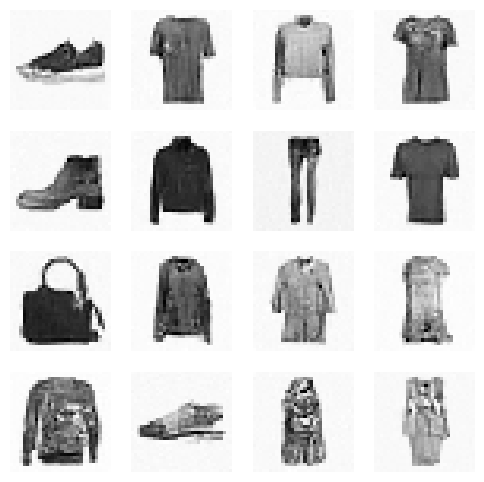

In [26]:
show_images(s[:16], imsize=1.5)

## Feats

In [27]:
clearn = TrainLearner(model,DataLoaders([],[(s,yb)]), loss_func=fc.noop, cbs=[DeviceCB()], opt_func=None)
feats2,y2 = clearn.capture_preds()
feats2 = feats2.float().squeeze()
feats2.shape , feats.shape

(torch.Size([256, 512]), torch.Size([10000, 512]))

- here `yb` and `y2` -> dummy
- `[(s,yb)] `-> as if one batch

In [28]:
# 1.Get means
means = feats.mean(0)
means.shape

torch.Size([512])

In [29]:
# 2.make a covariance matrix (correlation or each feature with the other)
covs = feats.T.cov()
covs.shape

torch.Size([512, 512])

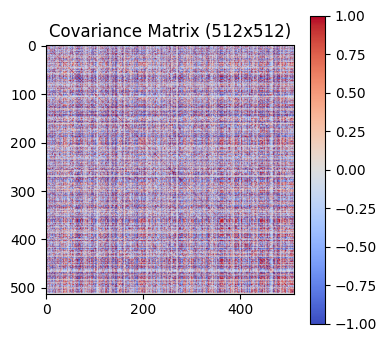

In [30]:
plt.figure(figsize=(4,4))
plt.imshow(covs.cpu(), cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar()
plt.title('Covariance Matrix (512x512)')
plt.show()

of course we can't get info by looking because it is so big

In [31]:
def _sqrtm_newton_schulz(mat, num_iters=100):
    mat_nrm = mat.norm()
    mat = mat.double()
    Y = mat/mat_nrm
    n = len(mat)
    I = torch.eye(n, n).to(mat)
    Z = torch.eye(n, n).to(mat)

    for i in range(num_iters):
        T = (3*I - Z@Y)/2
        Y,Z = Y@T,T@Z
        res = Y*mat_nrm.sqrt()
        if ((mat-(res@res)).norm()/mat_nrm).abs()<=1e-6: break
    return res

In [32]:
def _calc_stats(feats):
    feats = feats.squeeze()
    return feats.mean(0), feats.T.cov()

## FID

In [33]:
def _calc_fid(m1,c1,m2,c2):
#     csr = _sqrtm_newton_schulz(c1@c2)
    csr = tensor(linalg.sqrtm(c1@c2, 256).real)
    return (((m1-m2)**2).sum() + c1.trace() + c2.trace() - 2*csr.trace()).item()

In [34]:
s1,s2 = _calc_stats(feats),_calc_stats(feats2)

In [35]:
_calc_fid(*s1, *s2)

/tmp/ipykernel_32503/1909988476.py:3: DeprecationWarning: The `disp` argument is deprecated and will be removed in SciPy 1.18.0.
  csr = tensor(linalg.sqrtm(c1@c2, 256).real)


85.166748046875

## KID

In [36]:
def _squared_mmd(x, y):
    def k(a,b): return (a@b.transpose(-2,-1)/a.shape[-1]+1)**3
    m,n = x.shape[-2],y.shape[-2]
    kxx,kyy,kxy = k(x,x), k(y,y), k(x,y)
    kxx_sum = kxx.sum([-1,-2])-kxx.diagonal(0,-1,-2).sum(-1)
    kyy_sum = kyy.sum([-1,-2])-kyy.diagonal(0,-1,-2).sum(-1)
    kxy_sum = kxy.sum([-1,-2])
    return kxx_sum/m/(m-1) + kyy_sum/n/(n-1) - kxy_sum*2/m/n

In [37]:
def _calc_kid(x, y, maxs=50):
    xs,ys = x.shape[0],y.shape[0]
    n = max(math.ceil(min(xs/maxs, ys/maxs)), 4)
    mmd = 0.
    for i in range(n):
        cur_x = x[round(i*xs/n) : round((i+1)*xs/n)]
        cur_y = y[round(i*ys/n) : round((i+1)*ys/n)]
        mmd += _squared_mmd(cur_x, cur_y)
    return (mmd/n).item()

In [38]:
_calc_kid(feats, feats2)

0.66487056016922

## FID & KID class

In [39]:
class ImageEval:
    def __init__(self, model, dls, cbs=None):
        self.learn = TrainLearner(model, dls, loss_func=fc.noop, cbs=cbs, opt_func=None)
        self.feats = self.learn.capture_preds()[0].float().cpu().squeeze()
        self.stats = _calc_stats(self.feats)

    def get_feats(self, samp):
        self.learn.dls = DataLoaders([],[(samp, tensor([0]))])
        return self.learn.capture_preds()[0].float().cpu().squeeze()

    def fid(self, samp): return _calc_fid(*self.stats, *_calc_stats(self.get_feats(samp)))
    def kid(self, samp): return _calc_kid(self.feats, self.get_feats(samp))

In [40]:
ie = ImageEval(model, learn.dls, cbs=[DeviceCB()]) # learn.dls is the real data

In [41]:
%%time
round(ie.fid(s),4)

CPU times: user 2.97 s, sys: 8.45 ms, total: 2.98 s
Wall time: 216 ms


/tmp/ipykernel_32503/1909988476.py:3: DeprecationWarning: The `disp` argument is deprecated and will be removed in SciPy 1.18.0.
  csr = tensor(linalg.sqrtm(c1@c2, 256).real)


84.8911

In [42]:
%%time
round(ie.kid(s),4)

CPU times: user 873 ms, sys: 10.6 ms, total: 884 ms
Wall time: 90.9 ms


0.6627

/tmp/ipykernel_32503/1909988476.py:3: DeprecationWarning: The `disp` argument is deprecated and will be removed in SciPy 1.18.0.
  csr = tensor(linalg.sqrtm(c1@c2, 256).real)


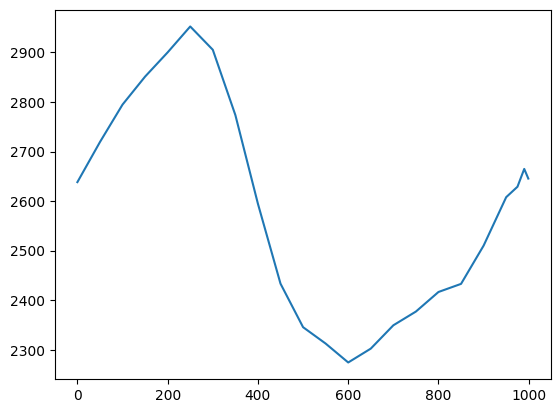

In [43]:
# plot fid from 0->1000 steps in the samples
xs = L.range(0,1000,50)+[975,990,999]
plt.plot(xs, [ie.fid(samples[i].clamp(-0.5,0.5)*2) for i in xs]);

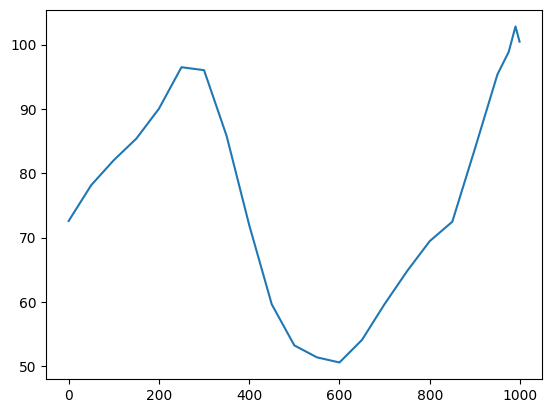

In [44]:
xs = L.range(0,1000,50)+[975,990,999]
plt.plot(xs, [ie.kid(samples[i].clamp(-0.5,0.5)*2) for i in xs]);

In [45]:
ie.fid(xb)

/tmp/ipykernel_32503/1909988476.py:3: DeprecationWarning: The `disp` argument is deprecated and will be removed in SciPy 1.18.0.
  csr = tensor(linalg.sqrtm(c1@c2, 256).real)


28.3095703125

looks a bit weird after 600, bec possibly the 0->1 bug in the model training,etc...(won't make a difference in understanding fid,etc..)

In [46]:
ie.kid(xb)

0.016541162505745888

# Using the inception model
most papers use this model as a standard

In [47]:
from pytorch_fid.inception import InceptionV3

In [48]:
a = tensor([1,2,3])
a.repeat((3,1))

tensor([[1, 2, 3],
        [1, 2, 3],
        [1, 2, 3]])

In [ ]:
class IncepWrap(nn.Module):
    def __init__(self):
        super().__init__()
        self.m = InceptionV3(resize_input=True) # resize any input to the expected size
    def forward(self, x): return self.m(x.repeat(1,3,1,1))[0]

- ` self.m(x.repeat(1,3,1,1))[0] ` ->  because inception expects 3 channels (we have is 1 channel)

In [ ]:
tds = dsd.with_transform(transformi)
dls = DataLoaders.from_dd(tds, bs, num_workers=fc.defaults.cpus)

In [ ]:
clean_mem()

my local memory is not enough for the inception model

In [ ]:
# ie = ImageEval(IncepWrap(), dls, cbs=[DeviceCB()])

In [ ]:
# %%time
# round(ie.fid(s),4)

In [ ]:
# round(ie.fid(xb),4)

In [ ]:
# %%time
# round(ie.kid(s),4)

In [ ]:
# round(ie.kid(xb),4)